In [22]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import EFC_learningfMRI.globals as gl
import EFC_learningfMRI.emg as emg
import EFC_learningfMRI.vis as vis
import EFC_learningfMRI.G_matrix as G_matrix
import PcmPy as pcm

subj100 day5: 200 trials, 10 channels, 1074 samples


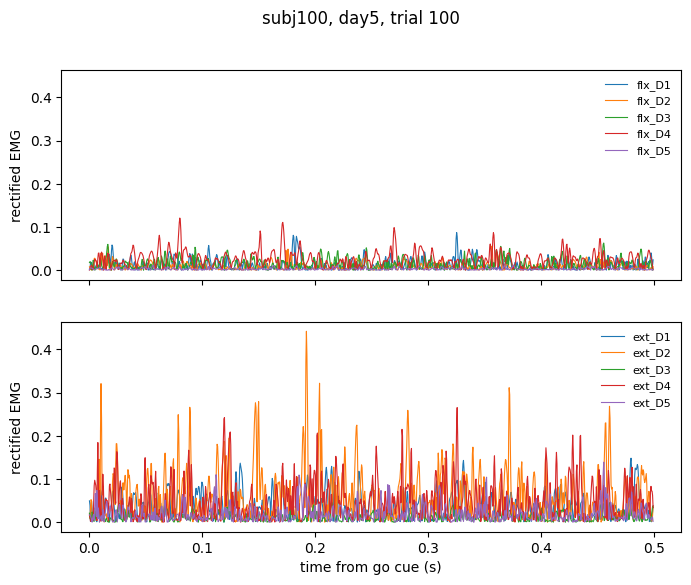

In [23]:

sn, day, trial = 100, 5, 100

# (trials, chan, samples), each trial from the go cue to go + 3.5 s, blocks stacked
emg_rect_seg = np.load(os.path.join(gl.baseDir, gl.emgDir, 'emg', f'day{day}', f'subj{sn}', 'emg_rect_segmented.npy'))
print(f'subj{sn} day{day}: {emg_rect_seg.shape[0]} trials, {emg_rect_seg.shape[1]} channels, {emg_rect_seg.shape[2]} samples')

time = np.arange(emg_rect_seg.shape[-1]) / gl.fsample['emg']   # s from the go cue

fig, axs = plt.subplots(2, 1, figsize=(8, 6), sharex=True, sharey=True)
for ax, muscle in zip(axs, ['flx', 'ext']):
    for c, ch in enumerate(emg.channels):
        if ch.startswith(muscle):
            ax.plot(time, emg_rect_seg[trial, c], lw=.8, label=ch)
    ax.set_ylabel('rectified EMG')
    ax.legend(loc='upper right', fontsize=8, frameon=False)
axs[-1].set_xlabel('time from go cue (s)')
fig.suptitle(f'subj{sn}, day{day}, trial {trial}')
plt.show()

chordID
11911    5
12129    5
12291    5
21291    5
21911    5
22911    5
91211    5
92122    5
Name: subNum, dtype: int64


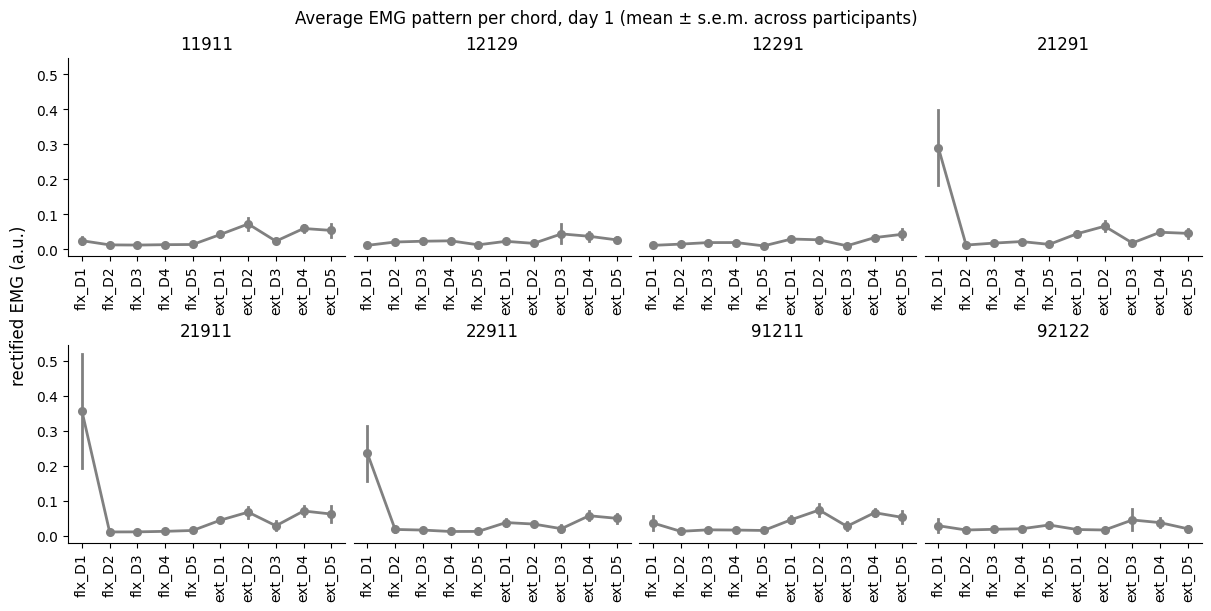

In [24]:
# avg pattern
day = 1

pattern = pd.read_csv(os.path.join(gl.baseDir, gl.emgDir, 'emg', f'{gl.emgDir}_pattern.tsv'), sep='\t')
pattern = pattern[(pattern.day == day) & (pattern.trialPoint == 1)]   # successful trials only, as in the Gs

# one value per participant x chord x channel, so the error bars are the s.e.m. across participants
pattern = pattern.melt(id_vars=['subNum', 'chordID'], value_vars=emg.channels, var_name='channel', value_name='emg')
pattern = pattern.groupby(['subNum', 'chordID', 'channel'], as_index=False)['emg'].mean()
print(pattern.groupby('chordID').subNum.nunique())

fig, axs = plt.subplots(2, 4, figsize=(12, 6), sharey=True, constrained_layout=True)
vis.plot_force_pattern(fig, axs, pattern, chords=gl.chordID, x='channel', y='emg', order=emg.channels,
                       color='grey', add_zero=False, instructed=False)
fig.supylabel('rectified EMG (a.u.)')
fig.suptitle(f'Average EMG pattern per chord, day {day} (mean ± s.e.m. across participants)')
plt.show()

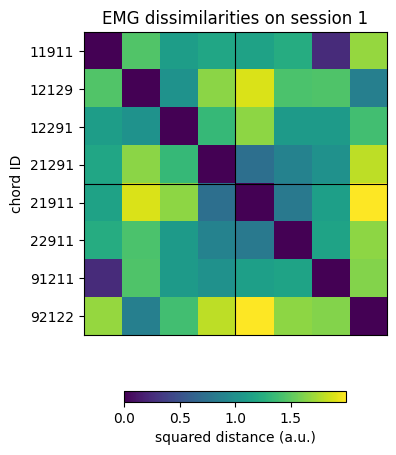

In [27]:
session = 1

fig, ax = plt.subplots()

vmin, vmax = 0, None

sns = emg.participants

G  = []
for sn in sns:
    G.append(np.load(os.path.join(gl.baseDir, gl.emgDir, 'pcm', f'subj{sn}', f'G_obs_raw.within_session.{session}.emg.npy')))
G  = np.array(G)

G_sort  = G_matrix.G_sorted(G, sns, order=gl.chordID, experiment='EFC_learningEMG')
D  = pcm.G_to_dist(G_sort)
D  = np.sign(D) * np.sqrt(np.abs(D))
im = ax.imshow(D.mean(axis=0), vmin=vmin, vmax=vmax)
ax.axhline(3.5, lw=.8, color='k')
ax.axvline(3.5, lw=.8, color='k')
ax.set_xticks([])
ax.set_yticks(np.arange(8))
#ax.set_xticklabels(gl.chordID, rotation=90)
ax.set_yticklabels(gl.chordID)
ax.set_title('EMG dissimilarities on session 1')

ax.set_ylabel('chord ID')

fig.colorbar(im, ax=ax, fraction=.03, label='squared distance (a.u.)', orientation='horizontal')

plt.show()

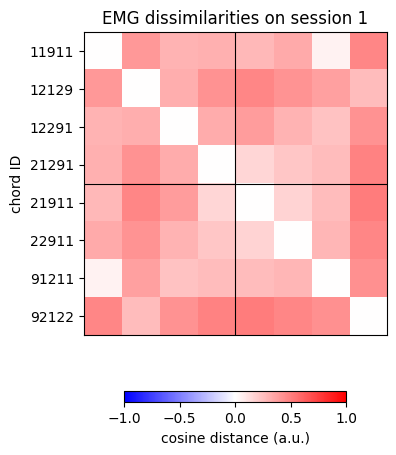

In [29]:
session = 1

fig, ax = plt.subplots()

vmin, vmax = -1, 1

sns = emg.participants

G  = []
for sn in sns:
    G.append(np.load(os.path.join(gl.baseDir, gl.emgDir, 'pcm', f'subj{sn}', f'G_obs_raw.within_session.{session}.emg.npy')))
G  = np.array(G)

G_sort  = G_matrix.G_sorted(G, sns, order=gl.chordID, experiment='EFC_learningEMG')
D  = 1 - pcm.G_to_cosine(G_sort)
D  = np.sign(D) * np.sqrt(np.abs(D))
im = ax.imshow(D.mean(axis=0), vmin=vmin, vmax=vmax, cmap='bwr')
ax.axhline(3.5, lw=.8, color='k')
ax.axvline(3.5, lw=.8, color='k')
ax.set_xticks([])
ax.set_yticks(np.arange(8))
#ax.set_xticklabels(gl.chordID, rotation=90)
ax.set_yticklabels(gl.chordID)
ax.set_title('EMG dissimilarities on session 1')

ax.set_ylabel('chord ID')

fig.colorbar(im, ax=ax, fraction=.03, label='cosine distance (a.u.)', orientation='horizontal')

plt.show()